# 00 — Data understanding, leakage checks and shared preparation

**Group 35:** Ruo Wu, Yichen Xie, Junzhe Xu, Zongliang Han

The common starting point for the four method notebooks. It shows what the
data contains, checks the frozen splits, and defines the 23 features every
method uses — so differences in results come from the methods, not from
four different pipelines.

| Section | What it shows |
|---|---|
| 1 | Dataset, field use and quality checks |
| 2 | The 165 missing hours |
| 3 | Frozen chronological split |
| 4 | Demand patterns (hour, day type, year, weather) |
| 5 | Leakage check |
| 6 | Shared 23 features and sample alignment |
| 7 | Summary |

## 1. Dataset
UCI Bike Sharing, hourly, Washington D.C., 2011–2012. Target: `cnt` (total
rentals in the hour) — a regression problem.

| Field | Use |
|---|---|
| `season`, `weathersit` | one-hot |
| `mnth`, `hr`, `weekday` | sin/cos (cyclical) |
| `holiday`, `workingday` | binary |
| `temp`, `atemp`, `hum`, `windspeed` | numeric (already normalised 0–1) |
| `yr` | excluded — would reveal which side of the time split a row is on |
| `casual`, `registered` | **excluded — they sum to `cnt` (leakage)** |
| `instant`, `dteday` | ordering / splitting only |

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for p in [Path.cwd(), *Path.cwd().parents]:            # locate the shared module
    hits = [q for q in (p, p / "src", p / "code" / "src") if (q / "bike_common.py").exists()]
    if hits:
        sys.path.insert(0, str(hits[0]))
        break
import bike_common as bc

bc.setup_plot_style()
raw = bc.load_raw()
print(f"Rows {len(raw):,} | {raw['dteday'].min().date()} to {raw['dteday'].max().date()}")
pd.Series({"duplicate instant": int(raw["instant"].duplicated().sum()),
           "missing raw cells": int(raw.isna().sum().sum()),
           "zero-demand hours": int((raw["cnt"] == 0).sum()),
           "target mean": round(raw["cnt"].mean(), 1),
           "target median": raw["cnt"].median(),
           "target max": int(raw["cnt"].max())}, name="value").to_frame()

Rows 17,379 | 2011-01-01 to 2012-12-31


,value
duplicate instant,0.0
missing raw cells,0.0
zero-demand hours,0.0
target mean,189.5
target median,142.0
target max,977.0


## 2. The 165 missing hours
LSTM and CNN need contiguous hours. `bike_common` rebuilds a complete hourly
grid, forward-fills weather and past demand (earlier values only) and keeps
`cnt` empty at missing hours, so they are never used as targets.

In [2]:
full_hours = pd.date_range(raw["dt"].min(), raw["dt"].max(), freq="h")
missing = full_hours.difference(pd.DatetimeIndex(raw["dt"]))
gap_id = (missing.to_series().diff() != pd.Timedelta("1h")).cumsum()
gaps = pd.Series(1, index=missing).groupby(gap_id.to_numpy()).size()
print(f"Missing hours {len(missing)} of {len(full_hours):,} ({len(missing) / len(full_hours):.2%}) "
      f"in {len(gaps)} gaps; longest {int(gaps.max())} hours")

Missing hours 165 of 17,544 (0.94%) in 75 gaps; longest 36 hours


## 3. Frozen chronological split
Agreed before any training: train 2011-01-01 → 2012-05-25, validation
→ 2012-09-12 (tuning and selection), test → 2012-12-31 (evaluated once).
A random split would put hours from the same week on both sides and give an
optimistic score; the time split asks "given the past, predict later".

Split sizes: {'train': 12139, 'validation': 2640, 'test': 2600} | all rows accounted for: True | overlaps: {'train_val': 0, 'train_test': 0, 'val_test': 0}


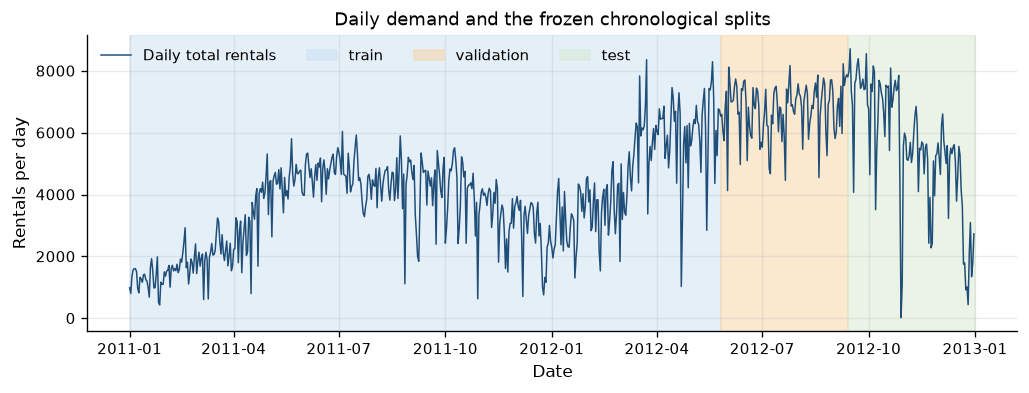

In [3]:
integrity = bc.check_split_integrity()
print("Split sizes:", integrity["rows"], "| all rows accounted for:",
      integrity["all_rows_accounted_for"], "| overlaps:", integrity["overlaps"])

daily = raw.groupby("dteday")["cnt"].sum()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(daily.index, daily.values, color="#1f4e79", lw=0.9, label="Daily total rentals")
for name, color in [("train", "#cfe2f3"), ("validation", "#f6d6a8"), ("test", "#d9ead3")]:
    part = pd.read_csv(bc.DATA_DIR / f"{name}.csv", parse_dates=["dteday"])
    ax.axvspan(part["dteday"].min(), part["dteday"].max() + pd.Timedelta(days=1),
               color=color, alpha=0.55, label=name)
ax.set(title="Daily demand and the frozen chronological splits", xlabel="Date",
       ylabel="Rentals per day")
ax.legend(ncol=4, loc="upper left")
bc.save_figure(fig, "fig_eda_split_timeline.png")
plt.show()

## 4. Demand patterns
Right-skewed target; two commute peaks on working days; one afternoon peak
at weekends.

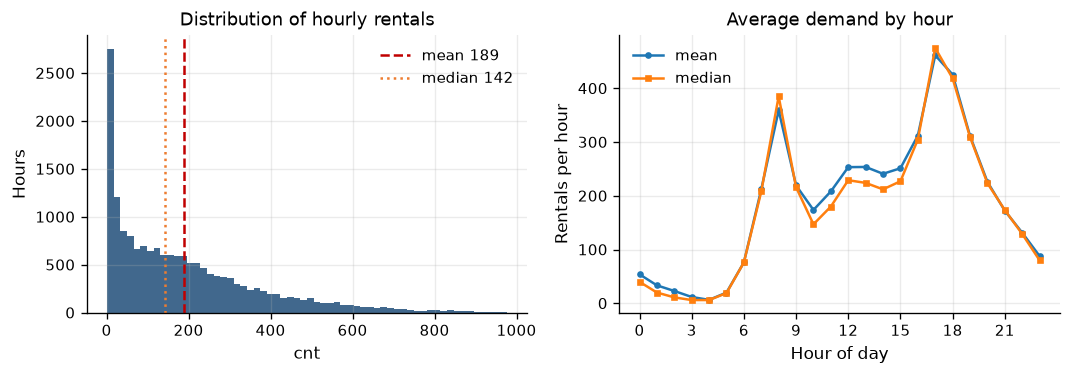

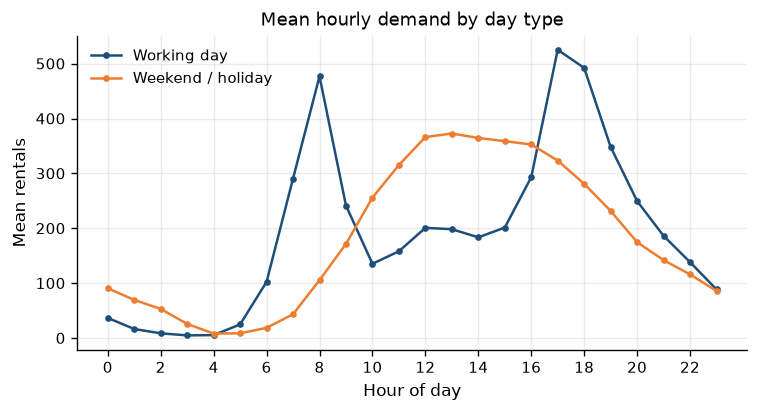

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(raw["cnt"], bins=60, color="#1f4e79", alpha=0.85)
axes[0].axvline(raw["cnt"].mean(), color="#c00000", ls="--", label=f"mean {raw['cnt'].mean():.0f}")
axes[0].axvline(raw["cnt"].median(), color="#ed7d31", ls=":", label=f"median {raw['cnt'].median():.0f}")
axes[0].set(title="Distribution of hourly rentals", xlabel="cnt", ylabel="Hours")
axes[0].legend()
profile = raw.groupby("hr")["cnt"].agg(["mean", "median"])
axes[1].plot(profile.index, profile["mean"], marker="o", ms=3, label="mean")
axes[1].plot(profile.index, profile["median"], marker="s", ms=3, label="median")
axes[1].set(title="Average demand by hour", xlabel="Hour of day", ylabel="Rentals per hour")
axes[1].set_xticks(range(0, 24, 3))
axes[1].legend()
plt.tight_layout()
bc.save_figure(fig, "fig_eda_target_and_hourly.png")
plt.show()

pivot = raw.assign(day_type=np.where(raw["workingday"] == 1, "Working day", "Weekend / holiday")
                   ).pivot_table(index="hr", columns="day_type", values="cnt", aggfunc="mean")
fig, ax = plt.subplots(figsize=(7.2, 3.4))
for column, color in [("Working day", "#1f4e79"), ("Weekend / holiday", "#ed7d31")]:
    ax.plot(pivot.index, pivot[column], marker="o", ms=3, color=color, label=column)
ax.set(title="Mean hourly demand by day type", xlabel="Hour of day", ylabel="Mean rentals")
ax.set_xticks(range(0, 24, 2))
ax.legend()
bc.save_figure(fig, "fig_eda_day_type.png")
plt.show()

2012 is clearly above 2011 (drift), so the later test period is harder. This
is why the shared features include causal demand history (lag / rolling
means) instead of the year flag. Temperature is the clearest weather driver;
rain and snow (`weathersit` 3–4) suppress demand.

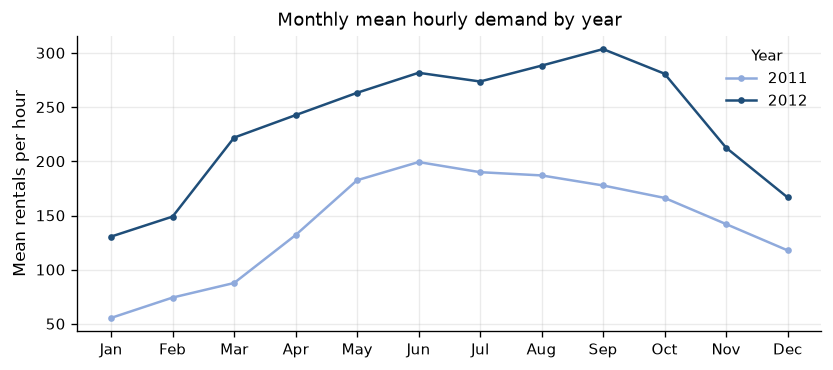

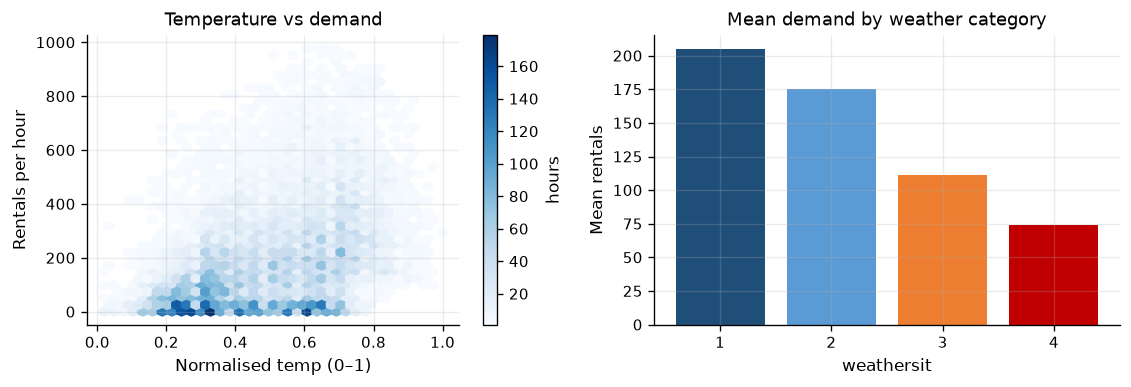

In [5]:
monthly = raw.groupby(["yr", "mnth"])["cnt"].mean().unstack(0)
monthly.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                 "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(8, 3.2))
for year, color, label in [(0, "#8faadc", "2011"), (1, "#1f4e79", "2012")]:
    ax.plot(monthly.index, monthly[year], marker="o", ms=3, color=color, label=label)
ax.set(title="Monthly mean hourly demand by year", ylabel="Mean rentals per hour")
ax.legend(title="Year")
bc.save_figure(fig, "fig_eda_year_drift.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
hb = axes[0].hexbin(raw["temp"], raw["cnt"], gridsize=35, cmap="Blues", mincnt=1)
axes[0].set(title="Temperature vs demand", xlabel="Normalised temp (0–1)", ylabel="Rentals per hour")
fig.colorbar(hb, ax=axes[0], label="hours")
weather_profile = raw.groupby("weathersit")["cnt"].mean()
axes[1].bar(weather_profile.index.astype(str), weather_profile.values,
            color=["#1f4e79", "#5b9bd5", "#ed7d31", "#c00000"])
axes[1].set(title="Mean demand by weather category", xlabel="weathersit", ylabel="Mean rentals")
plt.tight_layout()
bc.save_figure(fig, "fig_eda_weather.png")
plt.show()

## 5. Leakage check
`casual` and `registered` correlate almost perfectly with `cnt` because they
are its two parts, so they are excluded. Other correlations are moderate.

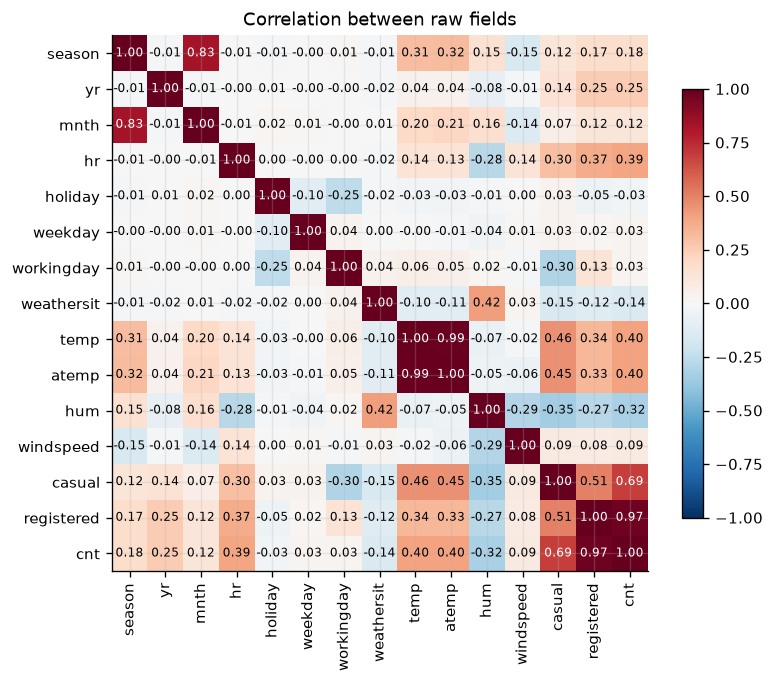

casual + registered == cnt for every row: True


In [6]:
corr_cols = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit",
             "temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
corr = raw[corr_cols].corr()
fig, ax = plt.subplots(figsize=(7.4, 5.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.55 else "black")
ax.set_title("Correlation between raw fields")
fig.colorbar(im, ax=ax, shrink=0.8)
bc.save_figure(fig, "fig_eda_correlation.png")
plt.show()
print("casual + registered == cnt for every row:",
      bool((raw["casual"] + raw["registered"] == raw["cnt"]).all()))

## 6. Shared 23 features and sample alignment
* 18 calendar / weather columns (one-hot season & weather, sin/cos month,
  hour, weekday, two flags, four weather values);
* 5 causal history columns: `lag1`, `lag24`, `lag168`, `roll24`, `roll168`,
  all from strictly earlier hours.

The first two weeks are warm-up and removed for every method. The scaler is
fitted on training rows only. The check below confirms the sequence builder
(LSTM, CNN) and the tabular builder (forest, autoencoder) give the same
targets, so all four methods are scored on identical rows.

In [7]:
d = bc.prepare_tabular()
seq = bc.prepare_sequences(window=168)
print("Modelling rows:", {k: len(d[f"y_{k}"]) for k in ("train", "validation", "test")})
print("Features:", ", ".join(d["feature_names"]))
print("Sequence shape (train):", seq["train"]["X"].shape,
      "| weekly CNN image:", bc.reshape_weekly(seq["train"]["X"][:2]).shape[1:])
print("Targets identical to tabular pipeline:",
      all(np.array_equal(seq[k]["y"], d[f"y_{k}"]) for k in ("train", "validation", "test")))

Modelling rows: {'train': 11816, 'validation': 2640, 'test': 2600}
Features: season_1, season_2, season_3, weather_1, weather_2, weather_3, mnth_sin, mnth_cos, hr_sin, hr_cos, wd_sin, wd_cos, holiday, workingday, temp, atemp, hum, windspeed, lag1, lag24, lag168, roll24, roll168
Sequence shape (train): (11816, 168, 23) | weekly CNN image: (23, 7, 24)
Targets identical to tabular pipeline: True


## 7. Summary
Clean data (17,379 rows, 165 missing hours handled causally); frozen,
non-overlapping splits; leakage fields excluded; one shared feature set and
one sample set for all four methods.

In [8]:
bc.save_json({
    "raw_rows": int(len(raw)), "raw_columns": int(len(raw.columns) - 1),
    "date_min": str(raw["dteday"].min().date()), "date_max": str(raw["dteday"].max().date()),
    "missing_hours": int(len(missing)), "longest_gap_hours": int(gaps.max()),
    "split_rows": {k: int(len(pd.read_csv(bc.DATA_DIR / f"{k}.csv")))
                   for k in ("train", "validation", "test")},
    "modelling_rows": {k: int(len(d[f"y_{k}"])) for k in ("train", "validation", "test")},
    "features": d["feature_names"],
    **{f"target_mean_{k}": float(d[f"y_{k}"].mean()) for k in ("train", "validation", "test")},
    "leakage_check_casual_plus_registered": bool(
        (raw["casual"] + raw["registered"] == raw["cnt"]).all()),
    "integrity": integrity,
}, "eda_summary.json")
print("Saved results/eda_summary.json")

Saved results/eda_summary.json
